<div style="border:1px solid #d8dee9; border-radius:8px; padding:16px 18px; background:#fbfcff; margin-bottom:14px;">
  <h1 style="margin:0 0 6px 0;">CraTEs Analysis Pipeline</h1>
  <h5 style="margin:0 0 6px 0;">07.04. - 07.08.2026 Master 1 Internship at Inserm Nice, in lab Gael Christofari.</h5>
  <p style="margin:0; color:#586069;"><strong>Author:</strong> Vinzent Aschir &nbsp; | &nbsp; <strong>Notebook:</strong> R kernel</p>
</div>

<details>
<summary><strong>Notebook metadata carried over from the Quarto source</strong></summary>

- Title: `CraTEs Analysis Pipeline`
- Format target in the source qmd: HTML with table of contents
- Execution settings in the source qmd: `echo: true`, `error: true`

</details>

## Pipeline overview

This notebook is an improved implementation for the craTEs pipeline, first used for recreation of the paper experiment. 

---

## 0 · Setup

example from the craTEs paper to get an understanding of the usage.

### ── Working directory ──

In [191]:
find_project_dir <- function(start = getwd()) {
  current <- normalizePath(start, mustWork = TRUE)
  repeat {
    if (file.exists(file.path(current, "scripts", "craTEs_own_function.R")) && dir.exists(file.path(current, "R"))) {
      return(current)
    }
    parent <- dirname(current)
    if (identical(parent, current)) {
      stop("Could not locate the craTEs repository root.", call. = FALSE)
    }
    current <- parent
  }
}

project_dir <- find_project_dir()
setwd(project_dir)

### ── Libraries ──

In [192]:
# libraries
library(Matrix)
library(data.table)
library(parallel)
library(dplyr)
library(ggplot2)
library(ggVennDiagram)
library(ggtext)

# craTEs library
library(craTEs)
ls("package:craTEs")

[1] "estimate_rmse_crossval"         "estimateRMSE"                  
 [3] "get_pseudocounts"               "getActivities"                 
 [5] "getSignifActivities"            "N_from_tsv"                    
 [7] "plot_signif_subfams"            "plot_signif_subfams_functional"
 [9] "plotActivities"                 "preprocess_E_N_for_activities" 
[11] "pval_from_fstat"                "row_center"                    
[13] "split_N_to_functional"

### ── Helper functions ──

**Local craTEs overrides.** The functions sourced from `local_craTEs_extension/` are backward-compatible because they keep the same function names and call style used by the package (`getActivities()`, `getSignifActivities()`, `preprocess_E_N_for_activities()`). They improve the package versions for these notebooks by adding hg38-aware preprocessing/exon-length handling, stricter matrix/name checks, and clearer diagnostics while preserving the original hg19 workflow.

In [193]:
source("scripts/craTEs_own_function.R")
source("scripts/own_mapping_f.R")
source("local_craTEs_extension/getActivities.R")
source("local_craTEs_extension/getSignifActivities.R")
source("local_craTEs_extension/preprocess_E_N_for_activities_hg38.R")

[1] "sourcing the custom function from crates"


### ── Global Variables ──


`handling` controls how duplicate gene rows are resolved throughout the pipeline.
  It is set once here so the same strategy applies consistently to both E and N.
- `discard` = All duplicates are removed rather than aggregated

- `Max Sum` = 	retain duplicates with the highest total expression across samples

- `Max Variance` =	retain duplicates with the highest expression variance across samples

- `Sum` = 		aggregate all duplicate rows elementwise 

- `Average` = 	average all duplicate rows elementwise

- `identical` = 	collapse only rows with that are exact duplicates throught all the gene counts


In [194]:
handling = "discard"

In [195]:
# log_dir is created once E_path and N_path are known.
log_dir <- NULL

---
## 1 · Expression Matrix E




Duplicate gene names are checked, resolved with `method = handling` and `threshold = 10`, and then the Excel date-mangled symbols are repaired before mapping.

### ── E - Matrix - CraTEs - CRISPRa/i - LTR5-Hs ──

> E - Expression matrix for NCCIT cells with CRISPRa/i against LTR5-Hs, LTR5A, LTR5B from [craTEs paper](https://www.researchgate.net/figure/craTEs-uncovers-cis-regulatory-TE-subfamilies-from-RNA-seq-A-Overview-of-the-craTEs_fig1_375556510).

The  [dataset GSE111332](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE111337) contains not only control group and the activating experiment VPR but also the repessing one with the KRAB complex. 



In [196]:
E_path <- "./data/Hg19/E_VPR-KRAB_CraTEs.txt.gz"

E <- fread(E_path)
gene_ids <- E$Geneid
E <- as.matrix(E[, -c(1,2), with = FALSE])  # drop Geneid and Length
rownames(E) <- gene_ids
dim(E)

[1] 26641    12

are the Gene ID row alreadz ENSEMBL IDs present that would be filtered as umapped? 

In [197]:
ensg_count <- sum(grepl("^ENSG", gene_ids))
cat(sprintf("Number of gene_ids matching ^ENSG: %d\n", ensg_count))

Number of gene_ids matching ^ENSG: 0


###  ── Count Check  ── 

In [198]:
count_table_to_check <- as.matrix(E)
storage.mode(count_table_to_check) <- "double"

integer_tolerance <- sqrt(.Machine$double.eps)
non_integer_mask <- is.finite(count_table_to_check) &
  abs(count_table_to_check - round(count_table_to_check)) > integer_tolerance

non_integer_idx <- which(non_integer_mask, arr.ind = TRUE)

if (nrow(non_integer_idx) == 0) {
  non_integer_entries <- data.frame(
    gene = character(),
    sample = character(),
    value = numeric(),
    stringsAsFactors = FALSE
  )
} else {
  non_integer_entries <- data.frame(
    gene = rownames(count_table_to_check)[non_integer_idx[, "row"]],
    sample = colnames(count_table_to_check)[non_integer_idx[, "col"]],
    value = count_table_to_check[non_integer_idx],
    stringsAsFactors = FALSE
  )
}

cat(sprintf(
  "Non-integer entries: %d / %d (%.4f%%)\n",
  nrow(non_integer_entries),
  length(count_table_to_check),
  100 * nrow(non_integer_entries) / length(count_table_to_check)
))
cat(sprintf("Affected genes: %d\n", length(unique(non_integer_entries$gene))))
cat(sprintf("Affected samples: %d\n", length(unique(non_integer_entries$sample))))

max_entries_to_print <- 200
if (nrow(non_integer_entries) == 0) {
  cat("All count entries are integer-like within tolerance.\n")
} else if (nrow(non_integer_entries) <= max_entries_to_print) {
  print(non_integer_entries)
} else {
  cat(sprintf(
    "Showing first %d entries. Full table is stored in non_integer_entries.\n",
    max_entries_to_print
  ))
  print(utils::head(non_integer_entries, max_entries_to_print))
}


Non-integer entries: 0 / 319692 (0.0000%)
Affected genes: 0
Affected samples: 0
All count entries are integer-like within tolerance.


### ── Duplication Check ──

the raw input may contain already duplicated gene names.

Two-step duplicate handling:
  1. `duplicate_stats()` audits how many rows share the same gene name.

In [199]:
duplicate_stats(rownames(E),E)

mapped_id,count,positions,row_sum,row_var
<chr>,<int>,<chr>,<chr>,<chr>
1-Mar,2,"2464,5894","6909,1708","125375,15740"
2-Mar,2,"2465,23666","2092,6627","6727,106104"


### ── Excel-naming Check ──

In [200]:
gene_ids <- transform_excel_dates(rownames(E)) 
rownames(E) <- gene_ids
duplicate_stats(rownames(E),E)

Found Excel date-mangled genes: 15-Sep, 1-Mar, 2-Mar, 10-Sep, 4-Mar, 7-Mar, 2-Sep, 1-Mar, 11-Sep, 3-Mar, 6-Mar, 11-Mar, 8-Sep, 14-Sep, 7-Sep, 1-Dec, 6-Sep, 8-Mar, 5-Mar, 9-Mar, 12-Sep, 1-Sep, 10-Mar, 9-Sep, 4-Sep, 2-Mar, 5-Sep, 3-Sep



mapped_id,count,positions,row_sum,row_var
<chr>,<int>,<chr>,<chr>,<chr>
MARCH1,2,"2464,5894","6909,1708","125375,15740"
MARCH2,2,"2465,23666","2092,6627","6727,106104"


### ── Resolve Duplicates ──

  2. `resolve_duplicates()` collapses them using the strategy in `handling`.
  3. If the input matrix contains a `Source` column, `resolve_duplicates()` reads it before duplicate resolution, removes it from the count matrix, and uses it to decide how `pre_mapped` rows should compete with translated mappings. By default, `pre_mapped = "pre-mapped"` keeps raw Ensembl IDs as the representative rows within duplicate groups; `pre_mapped = "same"` treats them like other mappings, and `pre_mapped = "unmapped"` drops them before resolving duplicates.

In [201]:
# E = resolve_duplicates(E, method = "sum") # one suggested by TE-SEq 
# E_id = resolve_duplicates(related_counts, method = "identical")
E = resolve_duplicates(E, method = "discard") # one as default in craTEs.
gene_ids <- rownames(E)

[resolve_duplicates] Method 'discard': 2 duplicate groups (4 rows) removed.



when opening Gene names in Excel, Genenames like MARCH1 are misinterpreted to datas: 1-Mar and therefore not foundable in databasis anymore.


---

## 2 · Count-Association Matrix N



### ── Load & reshape ──
N is the gene × TE-subfamily co-occurrence matrix. 
Each cell encodes how many times promoters of a given gene are associated with a given TE subfamily. It drives the linear model that infers TE activities from gene expression.


In [202]:
# # Different N matrices you want to use:

# # Hg 19 :
#     # 1. N counted, L = 100kb, from CraTEs_paper

        N_path <- "./data/Hg19/N_c_100_Hg19_craTEs.tsv"

#     # 2. N weighted, L = 2.5e5 kb, from CraTEs_paper
#     # https://zenodo.org/records/8117257

#         N_path <- "./data/Hg19/N_w_2.5e5_Hg19_craTEs.tsv"

# # Hg 38:
#     # 1. N counted, L = 100kb, from CraTEs_paper N_c_100_Hg38_craTEs.tsv
#     # https://zenodo.org/records/10390247

        # N_path <- "./data/Hg38/N_c_100_Hg38_craTEs.tsv"

#     # 2. N weighted, L = 2.5e5 kb, from CraTEs_paper
#     # https://zenodo.org/records/10390262
    
        # N_path <- "./data/Hg38/N_w_2.5e5_Hg38_craTEs.tsv"


In [203]:
## N - gene / TE subfamily - Count Association matrix

n_loaded <- load_count_association_matrix(N_path)
N <- n_loaded$N
genes_N <- n_loaded$genes_N

### ── Diagnostics-N ──

In [204]:
#duplicated genes: 
N_dub_stat = duplicate_stats(rownames(N))
sprintf("We have %d redundant duplicated Gene-rows in N in duplicated groups of %d ", N_dub_stat$redundant_rows, N_dub_stat$duplicate_groups)

# how dense is our N matrix? 
sprintf("the amount of 0 vals in the N matrix is %.2f%%", 100 * mean(N == 0))

[1] "We have 0 redundant duplicated Gene-rows in N in duplicated groups of 0 "

[1] "the amount of 0 vals in the N matrix is 92.23%"

---

## 3 · Gene ID Mapping Cache


E stores HGNC gene symbols, while N is indexed by Ensembl gene IDs.
The full server-dependent mapping procedure now lives in `scripts/gene_mapping.Rmd`, where the original BioMart, `org.Hs.eg.db`, and `mygene` heading structure is preserved as a rendered mapping report.

The notebook uses the cached TSV by default, because BioMart and MyGene server access can otherwise block every downstream step.
This section therefore only prepares the cache paths, optionally rebuilds the cache, loads the TSV, and reconstructs the objects expected by section 4.


### ── 3.1. Cache path and gene-name export ──

The cache name follows the active E and N inputs selected above.
The temporary gene-name TSVs are small handoff files for the Rmd rebuild script; they keep the expensive mapping step independent from the rest of the notebook.

In [205]:
# ── Cached mapping paths and gene-name extraction ──────────────────────────────
# The mapping cache name follows the active E_path and N_path selected above.
# When you switch datasets, update E_path/N_path beside the corresponding fread() calls.

if (!exists("E_path")) {
  stop("E_path is not defined. Set E_path in the active E loading cell before section 3.")
}
if (!exists("N_path")) {stop("N_path is not defined. Set N_path in the active N loading cell before section 3.")}

results_dir <- derive_activity_results_dir(
  E_path = E_path,
  N_path = N_path,
  results_parent = file.path(getwd(), "results")
)
figures_dir <- file.path(results_dir, "figures")
log_dir <- file.path(results_dir, "log")

dir.create(results_dir, showWarnings = FALSE, recursive = TRUE)
dir.create(figures_dir, showWarnings = FALSE, recursive = TRUE)
dir.create(log_dir, showWarnings = FALSE, recursive = TRUE)

options(crates.figures_dir = figures_dir, crates.log_dir = log_dir)
options(device = function(...) {grDevices::pdf(file = file.path(log_dir, "Rplots.pdf"), ...)})

mapping_inputs <- prepare_mapping_cache_inputs(
  E_path = E_path,
  N_path = N_path,
  gene_ids = gene_ids,
  genes_N = genes_N)

mapping_cache_path <- mapping_inputs$mapping_cache_path
mapping_report_path <- mapping_inputs$mapping_report_path
mapping_status_path <- mapping_inputs$mapping_status_path
e_gene_names_path <- mapping_inputs$e_gene_names_path
n_gene_names_path <- mapping_inputs$n_gene_names_path
mapping_dir <- dirname(mapping_cache_path)

results_dir
mapping_cache_path
mapping_report_path


[1] "/Users/vinzent/craTEs/results/results_E_VPR-KRAB_CraTEs_N_c_100_Hg19_craTEs"

[1] "/Users/vinzent/craTEs/results/results_E_VPR-KRAB_CraTEs_N_c_100_Hg19_craTEs/mapping/map_E_VPR-KRAB_CraTEs_N_c_100_Hg19_craTEs.tsv"

[1] "/Users/vinzent/craTEs/results/results_E_VPR-KRAB_CraTEs_N_c_100_Hg19_craTEs/mapping/report_E_VPR-KRAB_CraTEs_N_c_100_Hg19_craTEs.html"

### ── 3.2. Optional mapping rebuild report ──

The rebuild command is intentionally commented during normal notebook runs.
Uncomment it only when server access is available, run it once, then restart the kernel and return to the cached workflow.
The rendered HTML report is saved beside the TSV and records the full mapping process.

**Mapping rebuild options.**  
`--primary-mart "current"` uses the latest Ensembl annotation and is best for new analyses.  
`--primary-mart "v80"` uses Ensembl release 80, closer to older paper-era annotations.  
`--primary-mart` can also take a numeric Ensembl version, for example `"80"`.  
`--mirror "www"` uses the default Ensembl server; use `"useast"`, `"uswest"`, or `"asia"` if the default mirror is slow, unavailable, or returns HTTP errors.

In [206]:
# # ── Manual rebuild command ──────────────────────────────────────────────
# # Run this cell when BioMart/MyGene servers are reachable and the cached TSV
# # should be rebuilt. Skip this cell during normal cached notebook runs.

# source("scripts/own_mapping_f.R")

# mapping_inputs <- ensure_mapping_cache_inputs(
#   E_path = E_path,
#   N_path = N_path,
#   gene_ids = gene_ids,
#   genes_N = genes_N,
#   mapping_inputs = if (exists("mapping_inputs")) mapping_inputs else NULL
# )

# mapping_cache_path <- mapping_inputs$mapping_cache_path
# mapping_report_path <- mapping_inputs$mapping_report_path
# mapping_status_path <- mapping_inputs$mapping_status_path
# e_gene_names_path <- mapping_inputs$e_gene_names_path
# n_gene_names_path <- mapping_inputs$n_gene_names_path

# render_gene_mapping_script <- normalizePath("scripts/render_gene_mapping.R", mustWork = TRUE)

# rebuild_output <- system2(
#   "Rscript",
#   args = c(
#     "--vanilla", render_gene_mapping_script,
#     "--e-gene-names", e_gene_names_path,
#     "--n-gene-names", n_gene_names_path,
#     "--out", mapping_cache_path,
#     "--primary-mart", "current",
#     "--mirror", "www"),
#   stdout = TRUE,
#   stderr = TRUE)

# #eroor handling
# cat(paste(rebuild_output, collapse = "\n"), "\n")
# rebuild_status <- attr(rebuild_output, "status")
# if (is.null(rebuild_status)) rebuild_status <- 0L

# if (as.integer(rebuild_status) != 0L) {
#   stop(sprintf("Mapping rebuild failed with exit status %d.", as.integer(rebuild_status)), call. = FALSE)}

# if (!file.exists(mapping_cache_path)) {
#   stop(
#     mapping_cache_missing_message(
#       mapping_cache_path,
#       mapping_report_path
#     ),
#     call. = FALSE)}

# sprintf("Mapping cache ready: %s", mapping_cache_path)


### ── 3.3. Load cached mapping ──


In [207]:
# ── Load cached mapping ─────────────────
if (!file.exists(mapping_cache_path)) {
  stop(
    mapping_cache_missing_message(
      mapping_cache_path,
      mapping_report_path
    ),
    call. = FALSE)}

mapping_cache <- data.table::fread(mapping_cache_path, sep = "\t")

required_mapping_cols <- c(
  "hgnc_symbol",
  "ensembl_gene_id",
  "gene_biotype",
  "mapping_source",
  "in_N")

missing_mapping_cols <- setdiff(required_mapping_cols, colnames(mapping_cache))
if (length(missing_mapping_cols) > 0) {
  stop(paste(
    "Cached mapping is missing required columns:",
    paste(missing_mapping_cols, collapse = ", ")))}

mapping_cache[, hgnc_symbol := as.character(hgnc_symbol)]
mapping_cache[, ensembl_gene_id := as.character(ensembl_gene_id)]
mapping_cache[ensembl_gene_id == "", ensembl_gene_id := NA_character_]

map_combined <- setNames(
  mapping_cache$ensembl_gene_id,
  mapping_cache$hgnc_symbol)

# Keep the active E gene order and names, matching the previous section 3 output.
map_combined <- map_combined[gene_ids]

biotype_combined <- mapping_cache %>%
  filter(!is.na(ensembl_gene_id), !is.na(gene_biotype), gene_biotype != "") %>%
  dplyr::select(ensembl_gene_id, gene_biotype) %>%
  distinct(ensembl_gene_id, gene_biotype)

unmapped_final <- gene_ids[is.na(map_combined[gene_ids])]

mapped_only <- map_combined[!is.na(map_combined)]
ensembl_to_symbol <- setNames(names(mapped_only), unname(mapped_only))

sprintf(
  "Loaded cached mapping for %d E genes from %s",
  nrow(mapping_cache),
  mapping_cache_path)

[1] "Loaded cached mapping for 26641 E genes from /Users/vinzent/craTEs/results/results_E_VPR-KRAB_CraTEs_N_c_100_Hg19_craTEs/mapping/map_E_VPR-KRAB_CraTEs_N_c_100_Hg19_craTEs.tsv"

### ── 3.4. Cached mapping diagnostics ──

We analyse here only the resulted mapping we obtained through the [scripts/gene_mapping.Rmd](scripts/gene_mapping.Rmd) and a detailed data specific mapping pdf report can be found in the mapping location. 

Detailed BioMart, OrgDb and MyGene diagnostics are now documented in these gene_mapping.Rmd() report. and its mapping report details, html details are stored with the mapping. The notebook only verifies that the loaded cache overlaps N and contains the expected biotype information.

In [208]:
# Location of the mapping analysis of this dataset combination:

mapping_dir_rel <- sub(
  paste0("^", normalizePath(getwd(), winslash = "/"), "/"),
  "",
  normalizePath(dirname(mapping_cache_path), winslash = "/"))
  
print(mapping_dir_rel)

[1] "results/results_E_VPR-KRAB_CraTEs_N_c_100_Hg19_craTEs/mapping"


The mapping is so far not bijective, and contains a lot of duplicates. we should therefore not rely 

In [209]:
# ── Cached mapping diagnostics ───────────────────────────────────────────
sprintf(
  "%d of %d genes (%.2f%%) could not be mapped",
  length(unmapped_final),
  length(gene_ids),
  100 * length(unmapped_final) / length(gene_ids)
)

duplicate_stats(unname(map_combined[!is.na(map_combined)]),  include_table = FALSE)

[1] "1659 of 26637 genes (6.23%) could not be mapped"

$duplicate_groups
[1] 139

$affected_rows
[1] 294

$redundant_rows
[1] 155

  #### ── Unmapped Genes ──

In [210]:
  # ── Unmapped Genes ─────────────────────────────────────────

classes <- classify_unmapped(unmapped_final)
unmapped_class_summary <- summarise_unmapped_classes(classes)
unmapped_class_summary

class,n
<chr>,<int>
LOC,1273
SNORD,30
FLJ,36
LINC,39
KIAA,2
MIR,28
other,250


LOC = no Gene ID assigned yet 
long intergenic non-protein coding RNA 
SNORD = ncRNAs
FLJ = clone-based names (ncRNA)

In [211]:
# display_intersect(
#   unname(map_combined[!is.na(map_combined)]),
#   genes_N,
#   name_E = "E",
#   name_N = "N",
#   title  = "Gene overlap after cached mapping"
# )



# plot_mapping_distribution(
#   biotype_combined,
#   category_col = "gene_biotype",
#   highlight    = "protein_coding",
#   heading      = "All mappings combined: Biotype distribution",
#   n_thres      = 11)


<hr style="border: none; border-top: 2px dashed #999; height: 0;">

## 4 · Map Application, Filtering

Apply mapping to E and filter to protein-coding genes

This step applies the combined symbol-to-Ensembl mapping back to E, drops unmapped rows, and checks duplicates again. The protein-coding filter is then applied, because the paper analysis focuses protein-genes.

`apply_mapping_to_expression()` is sourced from the custom helper file and keeps the remapping step in one place. If the loaded mapping table contains a source column and at least one row is marked `pre-mapped` or `pre_mapped`, the helper adds a `Source` column to `E_mapped`; otherwise it returns a plain count matrix. `resolve_duplicates()` then reads that optional `Source` column and removes it before aggregating counts.

In [212]:
# ── Apply Mapping to E ────────────────────────────────────────────
E_mapped <- apply_mapping_to_expression(
  E,
  mapping = mapping_cache,
  gene_ids = gene_ids)

[apply_mapping_to_expression] Mapping source column found, but no pre-mapped rows were present.



#### ── Duplicate Resolvement ──

the handling of duplicates is defined globally and can be: 
- `discard` = All duplicates are removed rather than aggregated

- `Max Sum` = 	retain duplicates with the highest total expression across samples

- `Max Variance` =	retain duplicates with the highest expression variance across samples

- `Sum` = 		aggregate all duplicate rows elementwise 

- `Average` = 	average all duplicate rows elementwise

- `identical` = 	collapse only rows with that are exact duplicates throught all the gene counts

the duplicates we have in our expression matrix: 

In [213]:
duplicate_stats(rownames(E_mapped), E_mapped)

mapped_id,count,positions,row_sum,row_var
<chr>,<int>,<chr>,<chr>,<chr>
ENSG00000004866,2,"21260,21263","3487,9","54428,1"
ENSG00000078114,2,"1915,14880","2,1742","0,9738"
ENSG00000080854,2,"8642,13118","6685,6162","196722,202328"
ENSG00000086200,2,"8838,8839","14307,0","862303,0"
ENSG00000091986,2,"2852,10612","1966,74","20501,42"
ENSG00000101883,2,"10691,18487","36,58","8,10"
ENSG00000105793,2,"7724,11045","4307,0","59127,0"
ENSG00000105889,2,"11239,21323","14,629","2,1341"
ENSG00000108387,2,"2056,19440","19,900","2,7025"


resolving them through the global handling

In [214]:
E_resolved <- resolve_duplicates(E_mapped, method = handling, threshold = 10, pre_mapped = "pre_mapped")
duplicate_stats(rownames(E_resolved), E_resolved, include_table = FALSE)

[resolve_duplicates] Method 'discard': 139 duplicate groups (294 rows) removed.



$duplicate_groups
[1] 0

$affected_rows
[1] 0

$redundant_rows
[1] 0

In [215]:
# ── Verify biotype_combined covers all of E_resolved ────────
still_missing <- rownames(E_resolved)[
  !rownames(E_resolved) %in% biotype_combined$ensembl_gene_id
]

if (length(still_missing) > 0) {
  warning(sprintf(
    "%d genes in E_resolved still have no biotype — check mapping sources",
    length(still_missing)
  ))
  print(still_missing)
} else {
  message("All genes in E_resolved have a biotype entry.")
}

Warning message:
“2 genes in E_resolved still have no biotype — check mapping sources”


[1] "ENSG00000231755" "ENSG00000281501"


#### ── Filter to protein-coding Genes only ──

[1] "E before biotype filter: 24684 genes"

[1] "E after  biotype filter: 18999 genes"

Warning message:
“Vectorized input to `element_text()` is not officially supported.
ℹ Results may be unexpected or may change in future versions of ggplot2.”


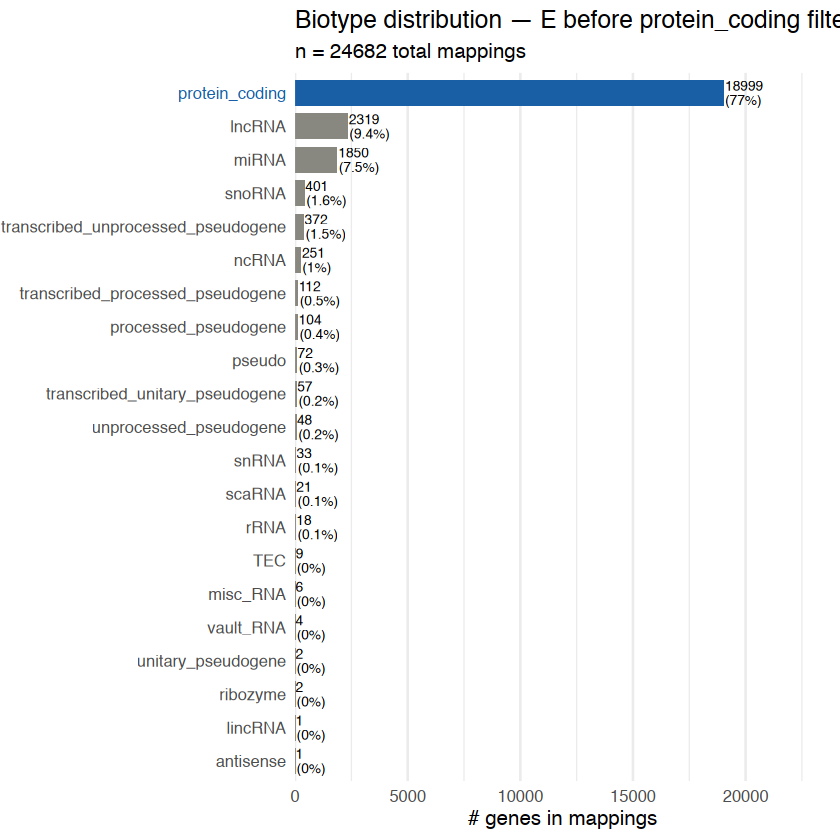

In [216]:
 # ── Filter E to protein_coding genes only ──────────────────
protein_coding_ensembl <- biotype_combined %>%
  filter(gene_biotype == "protein_coding") %>%
  pull(ensembl_gene_id)

E_filtered <- E_resolved[
  rownames(E_resolved) %in% protein_coding_ensembl,
  ,
  drop = FALSE
]

sprintf(
  "E before biotype filter: %d genes",
  nrow(E_resolved)
)

sprintf(
  "E after  biotype filter: %d genes",
  nrow(E_filtered)
)

plot_mapping_distribution(
  biotype_combined %>%
    filter(ensembl_gene_id %in% rownames(E_resolved)),
  category_col = "gene_biotype",
  highlight    = "protein_coding",
  heading      = "Biotype distribution — E before protein_coding filter")



---
## 5 · Preprocessing E and N for activities

The craTEs predefined preprocessing bundles several steps:
1. keeps only genes present in both E and N matrix

2. filter genes with less than 10 counts (low TE association)

3. remove TE-families that appear less than 150 times and stores in $lost_cols (low-predictor)

4. TPM normalisation to balance: seq-depth, rescaling, promotor-length

5. Add pseudocounts 

6. log2 transformation 

7. Row and Col Center expression matrix

#### ── Gene ID overlap before preprocessing ──

After duplicate resolution and biotype filtering, this diagnostic quantifies how well the reference N matrix covers the experiment-specific E matrix before preprocessing.

E genes: 18999
N genes: 20314
amount of genes we keep in E: 18398 (96.84% of E)
amount of genes we keep in N: 18398 (90.57% of N)
Common genes: 18398 (87.97% of union)
Only in E: 601 (3.16% of E, 2.87% of union)
Only in N: 1916 (9.43% of N, 9.16% of union)


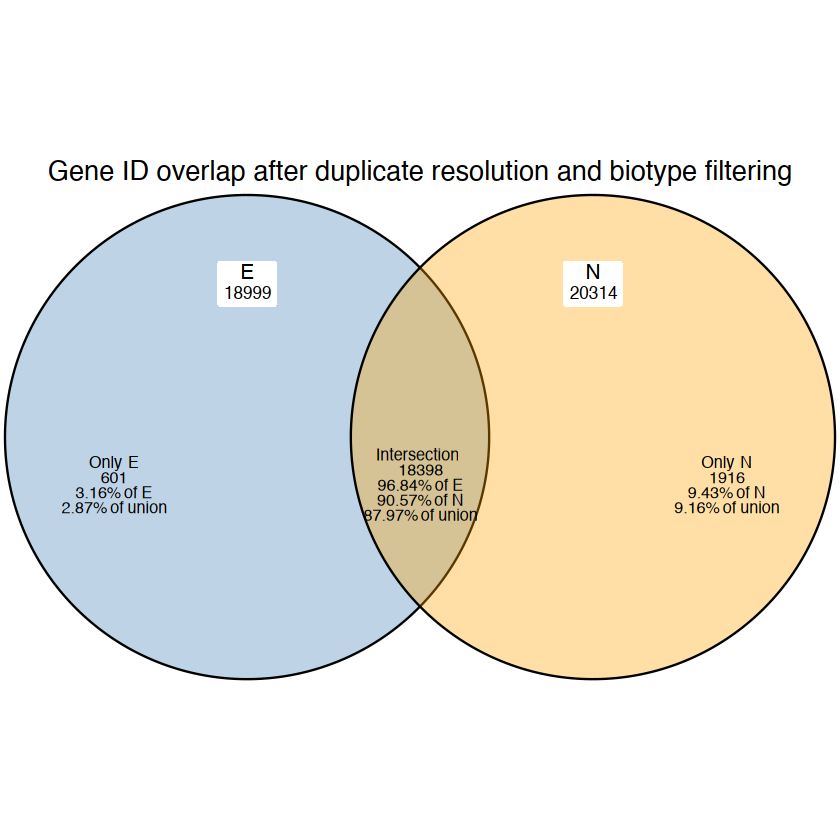

In [217]:
display_intersect(
  unique(rownames(E_filtered)),
  rownames(N),
  name_E = "E",
  name_N = "N",
  title = "Gene ID overlap after duplicate resolution and biotype filtering",
  plot = TRUE)

#### ── Filter low-predictor TE families ──

The TE-subfamily threshold diagnostic uses `threshold = 150` to show which columns preprocessing will discard later. TE subfamilies that are rarely inserted close to genes are assumed to provide weak predictors and are therefore filtered out in the next step.


p_npm threshold: 150
160 / 934 subfamilies (17.1%) are discarded
774 / 934 subfamilies (82.9%) are retained

Subfamilies below threshold (filtered):
  [1] "AluYc5"         "AmnSINE2"       "Charlie11"      "Charlie12"     
  [5] "Charlie1b_Mars" "Charlie4"       "Cheshire_Mars_" "Eulor1"        
  [9] "Eulor10"        "Eulor11"        "Eulor12"        "Eulor2A"       
 [13] "Eulor2B"        "Eulor2C"        "Eulor3"         "Eulor5A"       
 [17] "Eulor5B"        "Eulor6A"        "Eulor6B"        "Eulor6C"       
 [21] "Eulor6D"        "Eulor6E"        "Eulor7"         "Eulor8"        
 [25] "Eulor9A"        "Eulor9B"        "Eulor9C"        "HAL1N1_MD"     
 [29] "HERV-Fc1-int"   "HERV-Fc1_LTR1"  "HERV-Fc1_LTR2"  "HERV-Fc1_LTR3" 
 [33] "HERV-Fc2-int"   "HERV-Fc2_LTR"   "HERV15-int"     "HERV1_I-int"   
 [37] "HERV1_LTRa"     "HERV1_LTRb"     "HERV1_LTRc"     "HERV1_LTRd"    
 [41] "HERV1_LTRe"     "HERV30-int"     "HERVE_a-int"    "HERVFH19-int"  
 [45] "HERVH48-int"    "HERVI-int"  

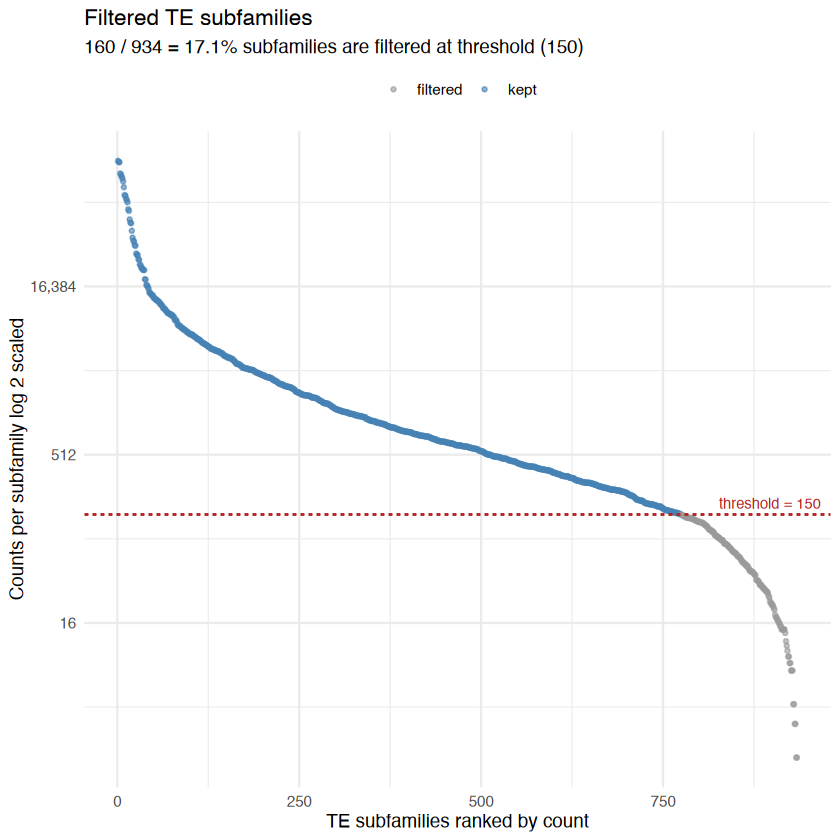

In [218]:
# which TE families would be discarded in preprocessing:
N <- as_count_association_matrix(N)
check_npm_threshold(N, threshold = 150)

#### ── Preprocessing ──

**Preprocessing settings.**  
`preprocess_E_N_for_activities()` is always sourced from `local_craTEs_extension/preprocess_E_N_for_activities_hg38.R`. The notebook sets `org` from the active `N_path`; hg38 uses `hg38_source = "EnsDb.Hsapiens.v86"`.

In [219]:
source("local_craTEs_extension/preprocess_E_N_for_activities_hg38.R")

preprocess_genome <- if (grepl("hg38", N_path, ignore.case = TRUE)) "hg38" else "hg19"
preprocess_exons_dir <- file.path(
  "data",
  if (identical(preprocess_genome, "hg38")) "Hg38" else "Hg19",
  "temp")

res <- preprocess_E_N_for_activities(
  count_table = E_filtered,
  N = N,
  log_tpm_plot_path = file.path(log_dir, "log_tpm.pdf"),
  org = preprocess_genome,
  exons_dir = preprocess_exons_dir,
  hg38_source = "EnsDb.Hsapiens.v86")

E_centered <- res$E_centered
N_filtered <- res$N

sprintf(
  "Preprocessed %d genes and %d TE predictors using %s.",
  nrow(E_centered),
  ncol(N_filtered),
  preprocess_genome
)

[1] "Preprocessed 15119 genes and 707 TE predictors using hg19."

#### ── Verify Preprocessing ──

E genes: 15119
N genes: 15119
amount of genes we keep in E: 15119 (100.00% of E)
amount of genes we keep in N: 15119 (100.00% of N)
Common genes: 15119 (100.00% of union)
Only in E: 0 (0.00% of E, 0.00% of union)
Only in N: 0 (0.00% of N, 0.00% of union)


$duplicate_groups
[1] 0

$affected_rows
[1] 0

$redundant_rows
[1] 0

$table
NULL

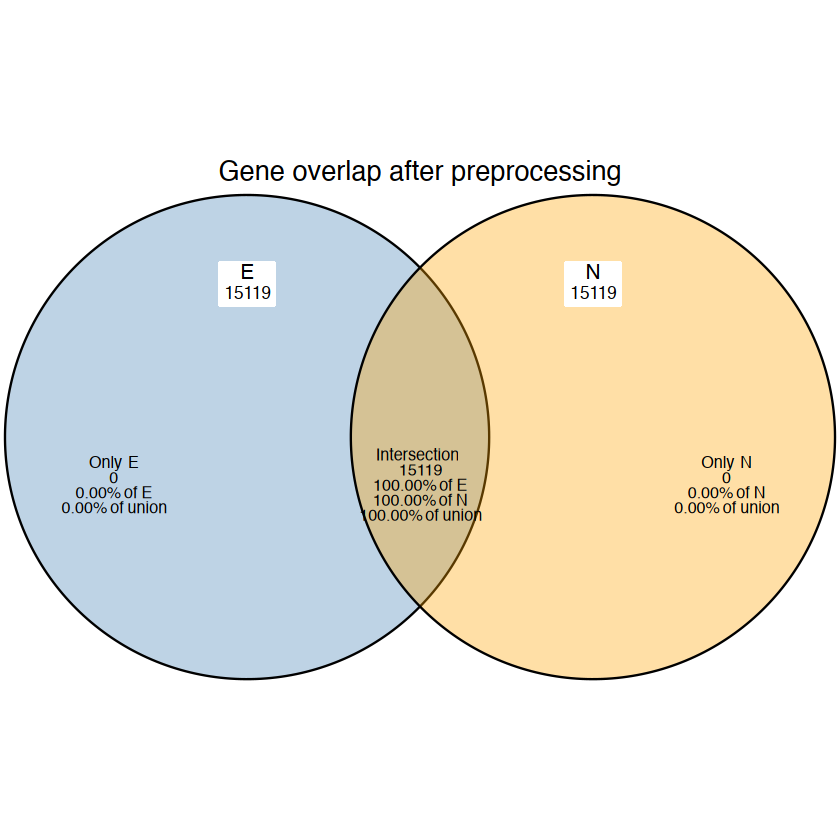

In [220]:
# Change to E_centered and N_filtered to inspect the matrices
# after preprocessing.
display_intersect(
  rownames(E_centered),
  rownames(N_filtered),
  name_E = "E",
  name_N = "N",
  title  = "Gene overlap after preprocessing")

duplicate_stats(
  rownames(E_centered),
  E_centered)

---

## 6 · Activity Estimation - penalised Linear Regression

### ──  Result Output Directory ──

We gather all the results for this experiment in a folder that is dependent on the matrix naming: 

In [221]:
# Location for exported activity results of this active E/N combination:
if (!exists("results_dir") || is.null(results_dir) || !nzchar(results_dir)) {
  results_dir <- derive_activity_results_dir(
    E_path = E_path,
    N_path = N_path,
    results_parent = file.path(getwd(), "results")
  )
}
figures_dir <- file.path(results_dir, "figures")
log_dir <- file.path(results_dir, "log")

dir.create(results_dir, showWarnings = FALSE, recursive = TRUE)
dir.create(figures_dir, showWarnings = FALSE, recursive = TRUE)
dir.create(log_dir, showWarnings = FALSE, recursive = TRUE)

options(crates.figures_dir = figures_dir, crates.log_dir = log_dir)
options(device = function(...) {grDevices::pdf(file = file.path(log_dir, "Rplots.pdf"), ...)})

results_dir_rel <- sub(
  paste0("^", normalizePath(getwd(), winslash = "/"), "/"),
  "",
  normalizePath(results_dir, winslash = "/"))

print(results_dir_rel)

[1] "results/results_E_VPR-KRAB_CraTEs_N_c_100_Hg19_craTEs"


### ──  6.1 - Activity Estimation  ──


This cell runs the solvment of the equation: 
> **E ≈ N x A**

`getActivities(E_centered, N_filtered)` and calcykates the TE activity matrix where the intercept row is removed. `A` contains only TE-subfamily activity coefficients.

| E | Sample 1 |   | N | TE_fam 1 | TE_fam 2 |   | A | A-score |
|---|----------|---|---|----------|----------|---|---|---------|
| Gene 1 | 10 | **=** | Gene 1 | 1 | 0 | **×** | TE_fam 1 | 3 |
| Gene 2 | 0 |   | Gene 2 | 2 | 1 |   | TE_fam 2 | 0 |

In [222]:
# ── CraTEs Activity ─────────────────────────────────────────
# local_craTEs_extension::getActivities override
act <- local({
  old_wd <- getwd()
  setwd(log_dir)
  on.exit(setwd(old_wd), add = TRUE)

  getActivities(E_centered, N_filtered)
})
A <- act$activities # TE activity matrix
A <- A[rownames(A) != "(Intercept)", , drop = FALSE]
colnames(A) <- colnames(E_centered)
A <- as.matrix(A)


[1] "Going parallel !"
Computing lambda max over  12  samples
Building the lambda gridRegressing activities of TFs for  12  samples
[1] "started new sample"
[1] "started new sample"
[1] "started new sample"
[1] "started new sample"
[1] "started new sample"
[1] "started new sample"
[1] "started new sample"
[1] "started new sample"
[1] "started new sample"
[1] "started new sample"
[1] "started new sample"
[1] "started new sample"
Finding the optimal lambda value across samples...
	... 1) Computing the per lambda MSE across samples
	... 2) retrieving the coefficients, crossval MSE, r_squared for the optimal lambda value


The boxplot is the first look at the elastic-net-like activity estimates, where many coefficients are expected to sit close to zero.

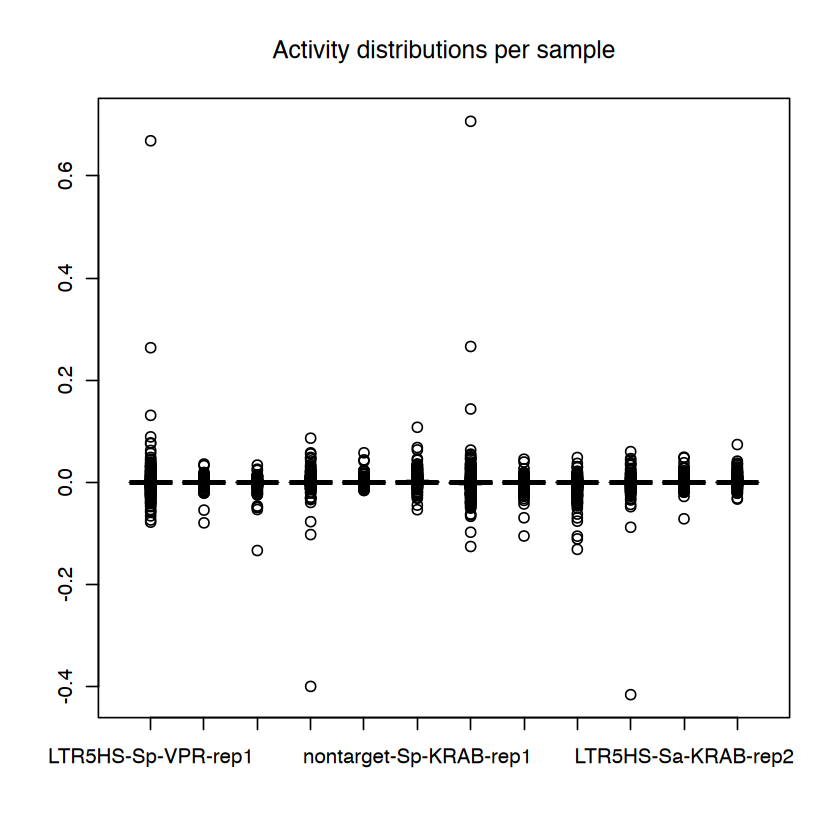

In [223]:
# Elastic net - penalised linear regression. (Activity coefficients close to 0) 
boxplot(as.matrix(A), main = "Activity distributions per sample")

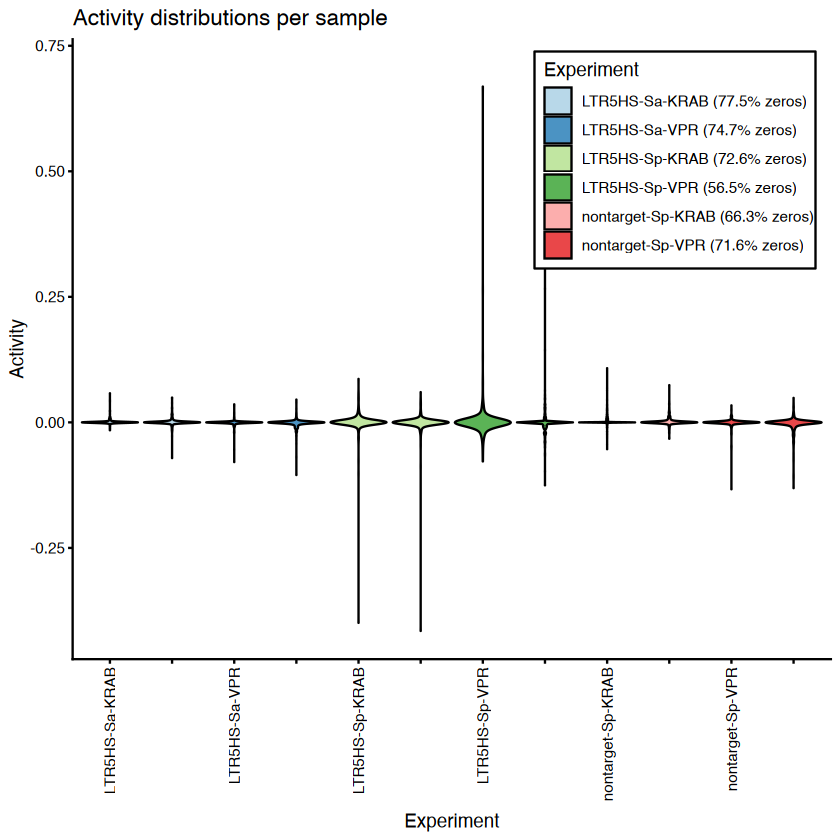

In [224]:
library(ggplot2)

sample_names <- colnames(A)
experiment <- sub("-rep[0-9]+$", "", sample_names)

ord <- order(experiment, sample_names)
sample_names <- sample_names[ord]
experiment <- experiment[ord]

A_long <- data.frame(
  sample = factor(rep(sample_names, each = nrow(A)), levels = sample_names),
  activity = as.vector(as.matrix(A[, sample_names, drop = FALSE])),
  experiment = rep(experiment, each = nrow(A))
)

zero_pct <- tapply(A_long$activity == 0, A_long$experiment, mean) * 100
experiment_labels <- paste0(names(zero_pct), " (", sprintf("%.1f%% zeros", zero_pct), ")")

x_labels <- experiment
x_labels[duplicated(experiment)] <- ""

ggplot(A_long, aes(x = sample, y = activity, fill = experiment)) +
  geom_violin(trim = TRUE, scale = "width", colour = "black", alpha = 0.8) +
  scale_fill_brewer(palette = "Paired", labels = experiment_labels) +
  scale_x_discrete(labels = x_labels) +
  theme_classic() +
  theme(
    axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1),
    axis.title.x = element_text(margin = margin(t = 10)),
    legend.position = c(0.98, 0.98),
    legend.justification = c("right", "top"),
    legend.background = element_rect(fill = "white", colour = "black")
  ) +
  labs(
    title = "Activity distributions per sample",
    x = "Experiment",
    y = "Activity",
    fill = "Experiment"
  )

In [225]:
# ranging plot files: move R's default plot file if the notebook kernel created it in the project root.
rplots_path <- file.path(log_dir, "Rplots.pdf")

if (file.exists("Rplots.pdf")) {
  if (file.exists(rplots_path)) {
    file.remove(rplots_path)
  }
  file.rename("Rplots.pdf", rplots_path)
}

**Output note.** The activity distribution plots are not meant to prove a biological result by itself; it checks whether the inferred activities have a plausible spread across samples before group-level comparisons.

In [226]:
# ── Save activity score matrix ─────────────────────────
activity_scores_tsv_path <- save_activity_score_matrix_tsv(
  activity_scores = A,
  output_path = file.path(results_dir, "activity_scores.tsv"),
  row_id_col = "te_subfamily",
  overwrite = TRUE)

activity_scores_tsv_rel <- sub(
  paste0("^", normalizePath(getwd(), winslash = "/"), "/"),
  "",
  normalizePath(activity_scores_tsv_path, winslash = "/"))

print(activity_scores_tsv_rel)

[1] "results/results_E_VPR-KRAB_CraTEs_N_c_100_Hg19_craTEs/activity_scores.tsv"


### ── 6.2 Model fit diagnostics ──

These diagnostics quantify how much variance in gene expression (`E`) is explained by the TE activity model (`N x A`) and how sparse the inferred activity matrix is.

The notebook builds the model-fit tables here, prints the summary, and saves the tables in the next cell to the same experiment-specific `results_dir` as `activity_scores.tsv`:

- `sample_activity_diagnostics.tsv`: one row per sample with condition, R², R²/R²max, and activity sparsity.

- `activity_fit_summary.tsv`: one overall row and one row per condition with mean R², mean R²/R²max, and mean sparsity.

`sample_conditions` is explicit so the same helper works for VPR/KRAB or for experiments with more than two conditions.

In [227]:
# ── Model fit diagnostics and export tables ───────────────────────
sample_conditions <- ifelse(
  grepl("VPR", colnames(A)), "VPR",
  ifelse(grepl("KRAB", colnames(A)), "KRAB", NA_character_)
)
sample_conditions <- setNames(sample_conditions, colnames(A))

if (any(is.na(sample_conditions))) {
  stop("Some samples could not be assigned to VPR or KRAB. Edit sample_conditions for this experiment.", call. = FALSE)
}

# Build diagnostics for printing and logging.
activity_fit_tables <- build_activity_fit_tables(
  act = act,
  A = A,
  sample_conditions = sample_conditions)

sample_activity_diagnostics <- activity_fit_tables$sample_activity_diagnostics
activity_fit_summary <- activity_fit_tables$activity_fit_summary
overall_fit <- activity_fit_summary[activity_fit_summary$scope == "overall", , drop = FALSE]

cat("\n── Model fit ───────────────────────────────\n")
cat(sprintf("Mean R²:              %.3f\n", overall_fit$mean_r2))
cat(sprintf("Mean R²/R²_max:       %.3f  (expected: 0.6-0.9)\n", overall_fit$mean_r2_ratio))
cat(sprintf("Sparsity of A:        %.2f%% zeros\n", overall_fit$mean_sparsity_percent))

cat("\nCondition means:\n")
print(
  activity_fit_summary[activity_fit_summary$scope == "condition", c(
    "condition", "n_samples", "mean_r2", "mean_r2_ratio", "mean_sparsity_percent"
  )],
  row.names = FALSE)


── Model fit ───────────────────────────────
Mean R²:              0.083


Mean R²/R²_max:       0.654  (expected: 0.6-0.9)
Sparsity of A:        69.86% zeros

Condition means:
 condition n_samples    mean_r2 mean_r2_ratio mean_sparsity_percent
       VPR         6 0.08319691     0.6648860              67.58604
      KRAB         6 0.08344389     0.6433142              72.13579


In [228]:
# ── Save model fit diagnostics ─────────────────────────
saved_model_fit_statistics <- rbind(
  write_result_object(
    input_dir = results_dir,
    name = "sample_activity_diagnostics",
    object = sample_activity_diagnostics,
    write_tsv = TRUE,
    write_rds = FALSE,
    overwrite = TRUE
  ),
  write_result_object(
    input_dir = results_dir,
    name = "activity_fit_summary",
    object = activity_fit_summary,
    write_tsv = TRUE,
    write_rds = FALSE,
    overwrite = TRUE
  )
)

saved_model_fit_statistics


name,format,path
<chr>,<chr>,<chr>
sample_activity_diagnostics,tsv,/Users/vinzent/craTEs/results/results_E_VPR-KRAB_CraTEs_N_c_100_Hg19_craTEs/sample_activity_diagnostics.tsv
activity_fit_summary,tsv,/Users/vinzent/craTEs/results/results_E_VPR-KRAB_CraTEs_N_c_100_Hg19_craTEs/activity_fit_summary.tsv


fits that weak are usual in linear regression in such a high dimensional space, where general gene expression is inferred from so many differential genes expressed. we wanna determine relative tendencies not excact predictions. if the fit is even weaker or activity sparsity is strange, the later targeted TE interpretation should be treated cautiously.

---

## 7 · Differential Activity

The group definitions are target- control. The targeted TE set is `c("LTR5_Hs", "LTR5A", "LTR5B")`, because these are the LTR5 subfamilies the experiment is designed around. The delta calculation is deliberately simple: treatment mean activity minus control mean activity, with the expected sign being positive for VPR activation and negative for KRAB repression.


In [229]:
# ── Define groups ──────────────────────────────────────
treatment_VPR  <- grep("LTR5HS.*VPR",      colnames(E_centered), value = TRUE)
control_VPR    <- grep("nontarget.*VPR",    colnames(E_centered), value = TRUE)
treatment_KRAB <- grep("LTR5HS.*KRAB",     colnames(E_centered), value = TRUE)
control_KRAB   <- grep("nontarget.*KRAB",  colnames(E_centered), value = TRUE)

### ── Delta activity for targeted TEs ──

In [230]:
# ── Delta activity for targeted TEs ────
# difference in activity when we activate or repress compared to normal. 
cat("\n── Delta activity (treatment - control) ────\n")
tes <- c("LTR5_Hs", "LTR5A", "LTR5B")
for (te in tes) {
  delta_vpr  <- mean(A[te, treatment_VPR])  - mean(A[te, control_VPR])
  delta_krab <- mean(A[te, treatment_KRAB]) - mean(A[te, control_KRAB])
  cat(sprintf("%-10s  VPR (activation):  %+.4f\n", te, delta_vpr))
  cat(sprintf("%-10s  KRAB (repression): %+.4f\n", te, delta_krab))
}
# Expected: LTR5_Hs positive for VPR, negative for KRAB


── Delta activity (treatment - control) ────
LTR5_Hs     VPR (activation):  +0.4300
LTR5_Hs     KRAB (repression): -0.2060
LTR5A       VPR (activation):  +0.1324
LTR5A       KRAB (repression): -0.0204
LTR5B       VPR (activation):  +0.0667
LTR5B       KRAB (repression): -0.0429


**Helper-based delta activity.** This cell uses the reusable `plot_delta_activity()` helper once per condition. `top_k` therefore selects the strongest TE-subfamily shifts within the active condition, while `te_subfamilies` forces targeted TEs into the output even when they are not in the top-k set.



VPR activation
Samples: 4 treatment, 2 control

 te_subfamily mean_treatment mean_control delta_activity
      LTR5_Hs     0.29790686 -0.132133569     0.43004043
        LTR5A     0.13243746  0.000000000     0.13243746
        LTR5B     0.06877133  0.002035416     0.06673591

KRAB repression
Samples: 4 treatment, 2 control

 te_subfamily mean_treatment mean_control delta_activity
      LTR5_Hs    -0.20366466  0.002331623    -0.20599629
        LTR5B    -0.04778866 -0.004850617    -0.04293805
        LTR5A    -0.04776369 -0.027320344    -0.02044335


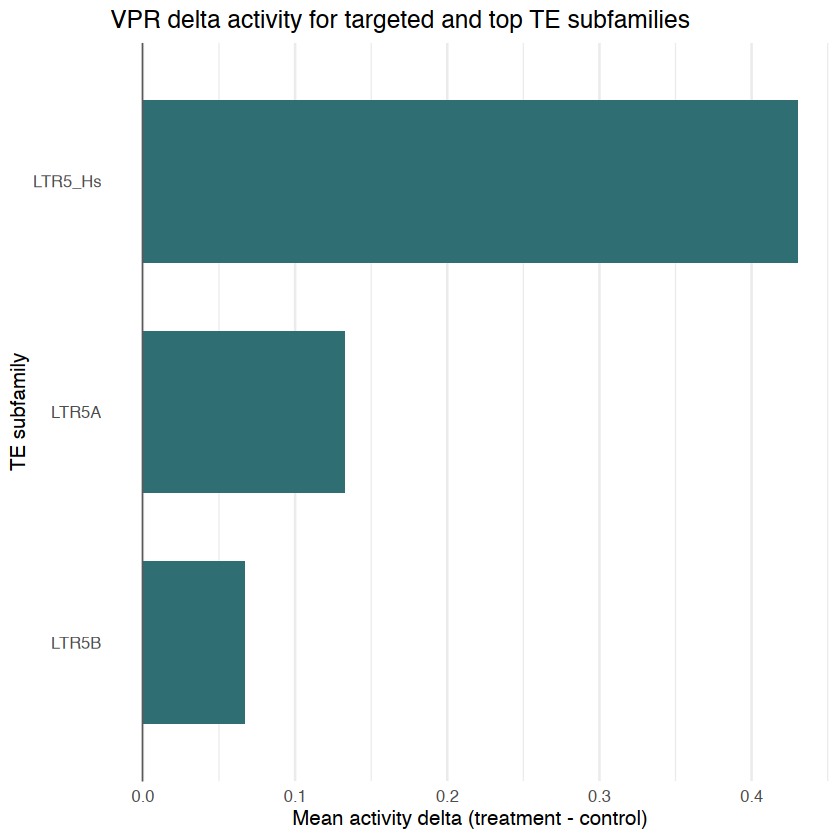

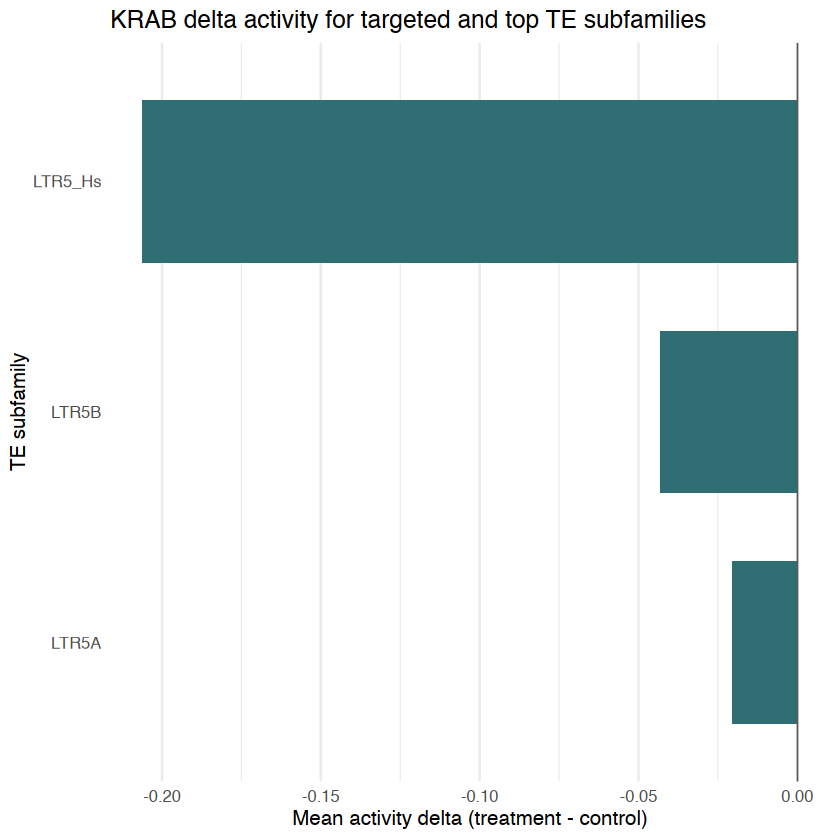

In [231]:
# ── Helper-based delta activity print and plot ─────────
targeted_tes <- c("LTR5_Hs", "LTR5A", "LTR5B")

delta_activity_VPR <- plot_delta_activity(
  activity_scores = A,
  treatment_samples = treatment_VPR,
  control_samples = control_VPR,
  condition_label = "VPR activation",
  top_k = 0,
  te_subfamilies = targeted_tes,
  title = "VPR delta activity for targeted and top TE subfamilies",
  treatment_label = "treatment",
  control_label = "control",
  plot = TRUE,
  print_table = TRUE
)

delta_activity_KRAB <- plot_delta_activity(
  activity_scores = A,
  treatment_samples = treatment_KRAB,
  control_samples = control_KRAB,
  condition_label = "KRAB repression",
  top_k = 0,
  te_subfamilies = targeted_tes,
  title = "KRAB delta activity for targeted and top TE subfamilies",
  treatment_label = "treatment",
  control_label = "control",
  plot = TRUE,
  print_table = TRUE
)


### ── Quality control — Activity patterns correlations accross replicates

Do the experiments in same condition conclude the same activity?
sp = standart cas9 
sa = targetting cas9


In [232]:
# ── Quality Control - Replicate correlation ─────────────
# Do the experiments in same condition conclude the same activity? 
activity_qc_pairs <- list(
  "Sp vs Sa KRAB rep1-rep2" = c("LTR5HS-Sp-KRAB-rep1", "LTR5HS-Sa-KRAB-rep1"),
  "Sp KRAB rep1 vs rep2"    = c("LTR5HS-Sp-KRAB-rep1", "LTR5HS-Sp-KRAB-rep2"),
  "Sp VPR rep1 vs rep2"     = c("LTR5HS-Sp-VPR-rep1",  "LTR5HS-Sp-VPR-rep2")
)

activity_pair_correlation_table <- activity_pair_correlations(
  activity_scores = A,
  sample_pairs = activity_qc_pairs,
  print_table = TRUE)



── Replicate correlations ──────────────────
Sp vs Sa KRAB rep1-rep2:     0.276
Sp KRAB rep1 vs rep2:        0.931
Sp VPR rep1 vs rep2:         0.973


**Output note.** High within-experiment replicate correlations support the activity estimation model. different target cas9 lead in less strong but still in the same direction.

---

## 8 · Significant TE activities for general gene expression 

The craTEs algorithm assigns shifts in gene expression per TE sufamily by refitting to an unpenalised linear Regression, to assign p-values and a statistical framework to the performed activity scores. 

we do not assign The contribution of specific TE subfamilies to specific Genes, but to the general gene expression. 
treatment vs control group are defined for each condition and calculated individually. 


In [233]:
# ── Significant-activity setup ──────────────────────────
# Experimentally perturbed target genes are removed before comparing CRISPRa/CRISPRi treatment with their controls.
exclude_ids <- c(
  "ENSG00000007402",
  "ENSG00000135333",
  "ENSG00000163286",
  "ENSG00000077150",
  "ENSG00000153982")

### ── CRISPRi VPR significant TE activities ──

In [234]:
# ── VPR significant activities + logging ───────────────
signif_VPR <- getSignifActivities(
  E_centered,
  N_filtered,
  treatment_group = treatment_VPR,
  control_group   = control_VPR,
  exclude_genes   = exclude_ids,
  contrast_mode   = "group_mean")

saved_VPR_signif_act <- save_signif_activity_result(
  input_dir = results_dir,
  condition = "VPR",
  signif_result = signif_VPR,
  write_tsv = TRUE,
  write_rds = FALSE,
  overwrite = TRUE
)

saved_VPR_signif_act

[1] "Starting new sample"


name,format,path
<chr>,<chr>,<chr>
VPR_signif_act,tsv,/Users/vinzent/craTEs/results/results_E_VPR-KRAB_CraTEs_N_c_100_Hg19_craTEs/VPR_signif_act.tsv


### ── CRISPRa KRAB significant TE activities ──

In [235]:
# ── KRAB significant activities + logging ──────────────
signif_KRAB <- getSignifActivities(
  E_centered,
  N_filtered,
  treatment_group = treatment_KRAB,
  control_group   = control_KRAB,
  exclude_genes   = exclude_ids,
  contrast_mode   = "group_mean")

saved_KRAB_signif_act <- save_signif_activity_result(
  input_dir = results_dir,
  condition = "KRAB",
  signif_result = signif_KRAB,
  write_tsv = TRUE,
  write_rds = FALSE,
  overwrite = TRUE
)

saved_KRAB_signif_act

[1] "Starting new sample"


name,format,path
<chr>,<chr>,<chr>
KRAB_signif_act,tsv,/Users/vinzent/craTEs/results/results_E_VPR-KRAB_CraTEs_N_c_100_Hg19_craTEs/KRAB_signif_act.tsv


### ── 8.1 - Significance model diagnostics ──

**Significance model diagnostics.** These values summarize the full unpenalised regression model used by `getSignifActivities()`, not one TE subfamily at a time.

- `f_statistic`: overall F-test statistic for whether the TE-predictor model explains the treatment-control expression delta better than an intercept-only model.
- `f_numdf`: numerator degrees of freedom for that F-test; roughly the number of independent predictors tested.
- `f_dendf`: denominator degrees of freedom; the residual degrees of freedom left after fitting the model.
- `f_p_value`: p-value for the overall F-test. Small values mean the full TE model explains more variation than the null model.
- `r_squared`: fraction of delta-expression variance explained by the fitted model.
- `rss`: residual sum of squares, meaning the variation still left unexplained after fitting. Lower RSS indicates a closer fit.

In [236]:
# ── Significant-activity model diagnostics ─────────────
signif_model_diagnostics_table <- rbind(
  signif_model_diagnostics(signif_VPR,  condition = "VPR",  print_table = FALSE),
  signif_model_diagnostics(signif_KRAB, condition = "KRAB", print_table = FALSE))

diagnostic_display_cols <- c(
  "condition", "f_statistic", "f_numdf", "f_dendf",
  "f_p_value", "r_squared", "rss")

print(
  signif_model_diagnostics_table[, diagnostic_display_cols, drop = FALSE],
  row.names = FALSE)

 condition f_statistic f_numdf f_dendf     f_p_value r_squared      rss
       VPR    2.916854     707   14406 4.091287e-120 0.1252240 4193.641
      KRAB    4.408438     707   14406 1.267195e-260 0.1778695 1522.795


### ── 8.2 - Activity boxplots per targeted TE ── 

The boxplots focus only on `LTR5_Hs`, `LTR5A`, and `LTR5B`, splitting each target TE into CRISPRa and CRISPRi panels. Three target TEs across two perturbation systems compared to their control group.
  - _X-Axis_: all samples grouped by sample group in their experiment (treatment vs. control)
  
  - _one point in boxplot_: activity coefficient associated to this TE as a log2fold change if an insertion occors depicted per sample-group within an experiment. 
  
  - _Y-Axis_: regulatory coefficients of target TE for samples within one sample-group (up or down regulated, tar vs ctrl)


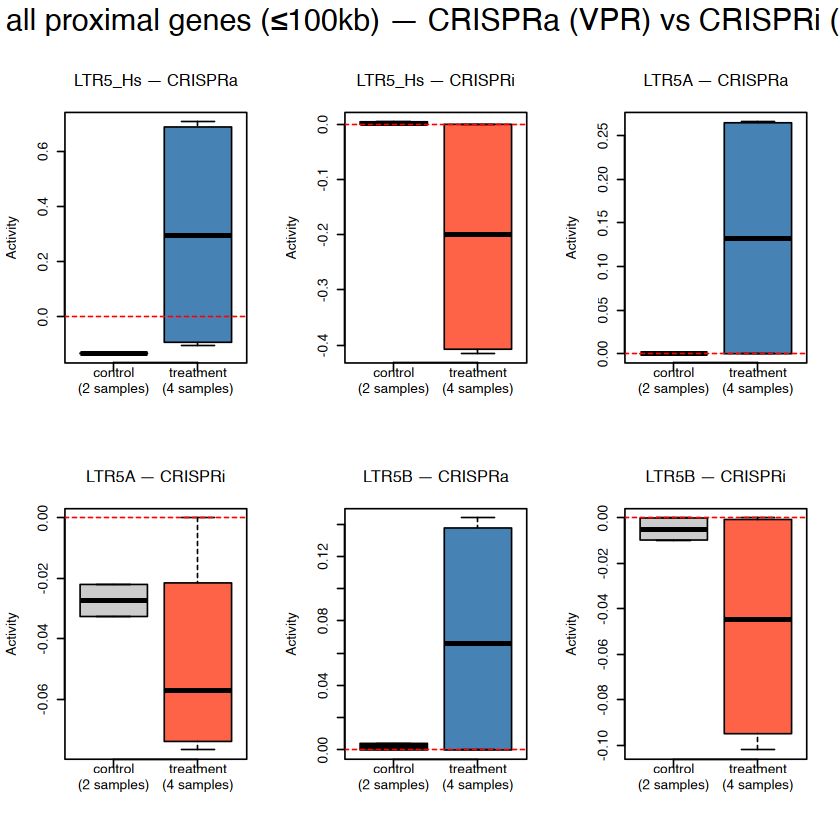

In [237]:
# ── Activity boxplots per targeted TE ─────────────────
# Plots: specific TE sequences are active or repressed or normal.
# X-Axsis: all samples grouped by sample group (treatment vs. control)
# one point in boxplot: activity coefficient of all genes close to this specific TE per sample-group for the specific TE
# Y-Axsis: regulatory coefficients of target TE for samples within one sample-group (up or down regulated,tar vs ctrl)
par(mfrow = c(2, 3), oma = c(0, 0, 3, 0))
for (te in tes) {
  # CRISPRa data
  data_vpr  <- list(A[te, control_VPR], A[te, treatment_VPR])
  names_vpr <- c(sprintf("control\n(%d samples)", length(control_VPR)),
                 sprintf("treatment\n(%d samples)", length(treatment_VPR)))
  
  boxplot(data_vpr,
          names = names_vpr, # Hier werden die neuen Namen gesetzt
          main  = sprintf("%s — CRISPRa", te),
          ylab  = "Activity",
          col   = c("grey80", "steelblue"))
  
  abline(h = 0, lty = 2, col = "red")
  
  # 2. CRISPRi Daten vorbereiten
  data_krab  <- list(A[te, control_KRAB], A[te, treatment_KRAB])
  names_krab <- c(sprintf("control\n(%d samples)", length(control_KRAB)),
                  sprintf("treatment\n(%d samples)", length(treatment_KRAB)))
  
  boxplot(data_krab,
          names = names_krab,
          main  = sprintf("%s — CRISPRi", te),
          ylab  = "Activity",
          col   = c("grey80", "tomato"))
  
  abline(h = 0, lty = 2, col = "red")}

mtext("Inferred cis-regulatory activity of targeted TE subfamilies (LTR5_Hs, LTR5A, LTR5B)\nacross all proximal genes (≤100kb) — CRISPRa (VPR) vs CRISPRi (KRAB)", 
      outer = TRUE, cex = 1.5, font = 2, line = 1)
par(mfrow = c(1,1), oma = c(0,0,0,0))  # reset


**Output note.** Tendency are the upregulating experiments expressing positive activity scores and the negative negative ones? 
More direct than the volcano plot because each panel answers one targeted-TE question.

###  ── 8.3 - Activity across all samples ordered by group ──

for each TE subfamily, plot the activity across all samples

[1] "sourcing the custom function from crates"


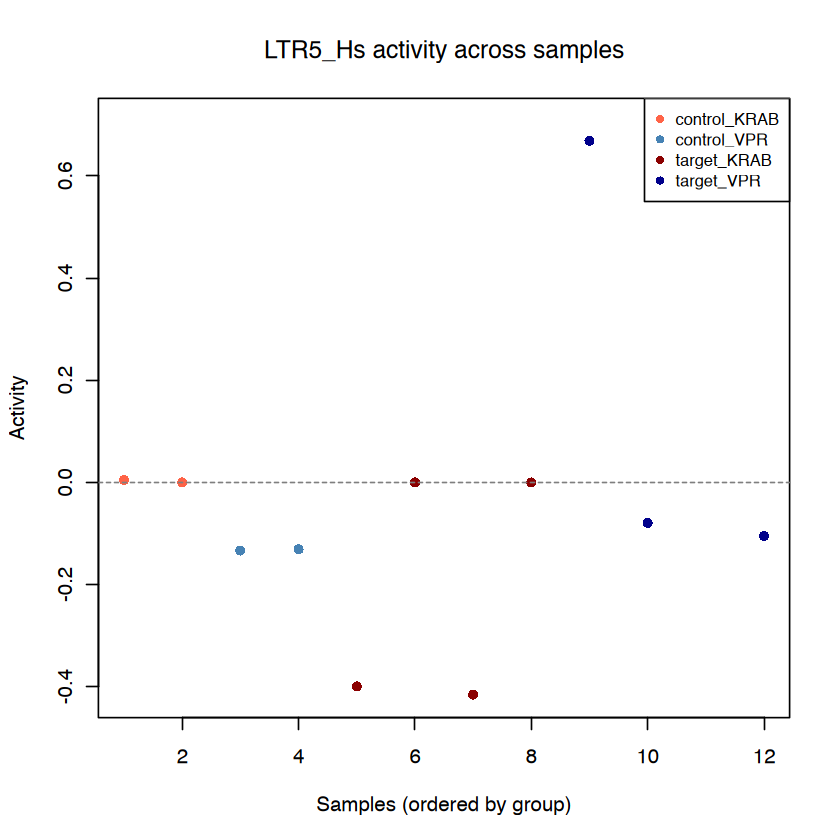

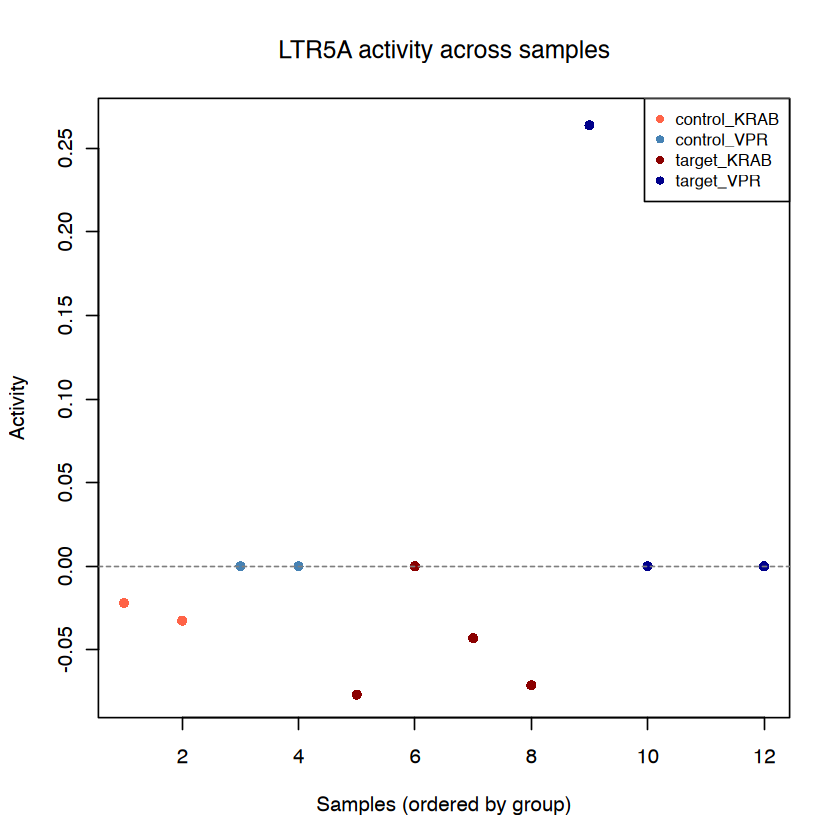

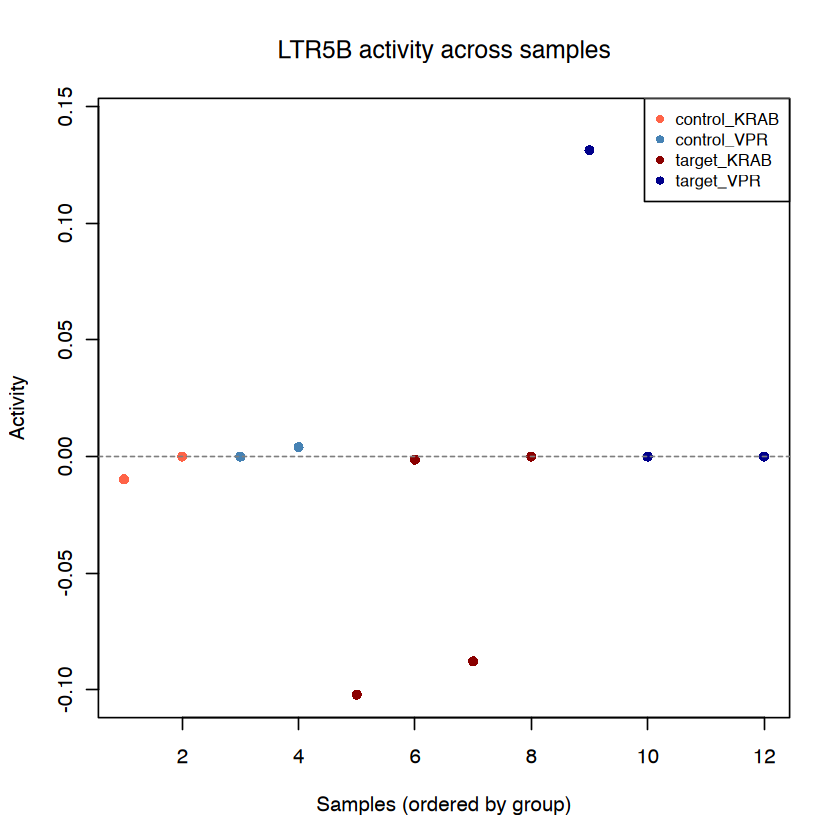

In [238]:
# ── Activity across all samples ordered by group ───────
# for each TE subfamily, plot the activity across all samples
source("scripts/craTEs_own_function.R")

plot_activity_across_samples(
  activity_scores = A,
  te_subfamilies = tes
)

**Output note.** here we want to spot whether a delta is driven by all samples or by one unusual point.

---

## 9 · Target gene matrix

In [239]:
# ── Preprocessed object for target-matrix calculations ──
preprocessed <- list(E_centered = E_centered, N = N_filtered)

 getTargetMatrix() estimates which genes depend most strongly on each TE subfamily 
  by computationally silencing TE subfamilies in the N matrix and measuring the loss in prediction accuracy.
  Which genes are most dependent on each TE-subfamily signal?
  Run separately for VPR (activation) and KRAB (repression)

### ── 9.1 - VPR target gene matrix ──

In [240]:
# ── VPR target gene matrix ─────────────────────────────
target_genes_VPR <- getTargetMatrix(signif_VPR, preprocessed)

### ── 9.2 - KRAB target gene matrix ──

In [241]:
# ── KRAB target gene matrix ────────────────────────────
target_genes_KRAB <- getTargetMatrix(signif_KRAB, preprocessed)

### ── 9.3 - Combined LTR5_Hs target-gene summary ──

In [242]:
# ── Combined LTR5_Hs target-gene summary ───────────────
# Top genes most impacted by LTR5_Hs perturbation
top_VPR  <- sort(target_genes_VPR[, "LTR5_Hs"],  decreasing = TRUE)
top_KRAB <- sort(target_genes_KRAB[, "LTR5_Hs"], decreasing = TRUE)

# Rank positions within each condition
rank_VPR <- rank( -top_VPR, ties.method = "min")

rank_KRAB <- rank( -top_KRAB, ties.method = "min")

# Union of the top 20 genes in the two conditions
candidate_genes <- union( names(top_VPR)[1:20], names(top_KRAB)[1:20])

target_summary <- data.frame(
  ensembl_gene_id = candidate_genes,
  hgnc_symbol     = unname(ensembl_to_symbol[candidate_genes]),
  VPR_score       = unname(top_VPR[candidate_genes]),
  KRAB_score      = unname(top_KRAB[candidate_genes]),
  VPR_rank        = unname(rank_VPR[candidate_genes]),
  KRAB_rank       = unname(rank_KRAB[candidate_genes]),
  stringsAsFactors = FALSE)
target_summary$mean_score <- rowMeans(
  target_summary[, c("VPR_score", "KRAB_score")],
  na.rm = TRUE)

target_summary$shared_top20 <- (
  target_summary$VPR_rank <= 20 &
    target_summary$KRAB_rank <= 20)

target_summary <- target_summary[
  order(
    target_summary$shared_top20,
    target_summary$mean_score,
    decreasing = TRUE),]

cat("
Combined LTR5_Hs target-gene summary VPR/KRAB:
")
print(target_summary)


Combined LTR5_Hs target-gene summary VPR/KRAB:
   ensembl_gene_id hgnc_symbol   VPR_score KRAB_score VPR_rank KRAB_rank
9  ENSG00000197721        CR1L  18.1407125 16.4192564        9         8
21 ENSG00000176979      TRIM60   5.9997370 56.3830855       76         1
3  ENSG00000073849     ST6GAL1  24.2672138 12.2304114        3        24
23 ENSG00000196189      SEMA4A   8.8443132 26.8531595       49         3
5  ENSG00000170373        CST1  21.6026720 12.1508523        5        25
8  ENSG00000183628       DGCR6  19.0816224 12.1222831        8        26
2  ENSG00000059915         PSD  24.3741558  6.2556601        2        78
1  ENSG00000108950      FAM20A  27.1349063  1.9765113        1       205
34 ENSG00000142405      NLRP12  12.2240657 14.3714309       24        15
15 ENSG00000125966       MMP24  13.4750851 10.3679325       15        38
13 ENSG00000119227        PIGZ  14.8692233  8.5667305       13        51
4  ENSG00000117228        GBP1  23.3994956 -0.3477843        4     14871
30 

**Output note.** The VPR and KRAB tables are just a strong approximation through the relative contribution to the loss, no p-value of these matrices are made in the paper. 

### ── 9.4 - Comparable heatmaps of target contributions ──

Saved: /Users/vinzent/craTEs/results/results_E_VPR-KRAB_CraTEs_N_c_100_Hg19_craTEs/figures/target_matrix_full_VPR.pdf

Saved: /Users/vinzent/craTEs/results/results_E_VPR-KRAB_CraTEs_N_c_100_Hg19_craTEs/figures/target_matrix_full_KRAB.pdf



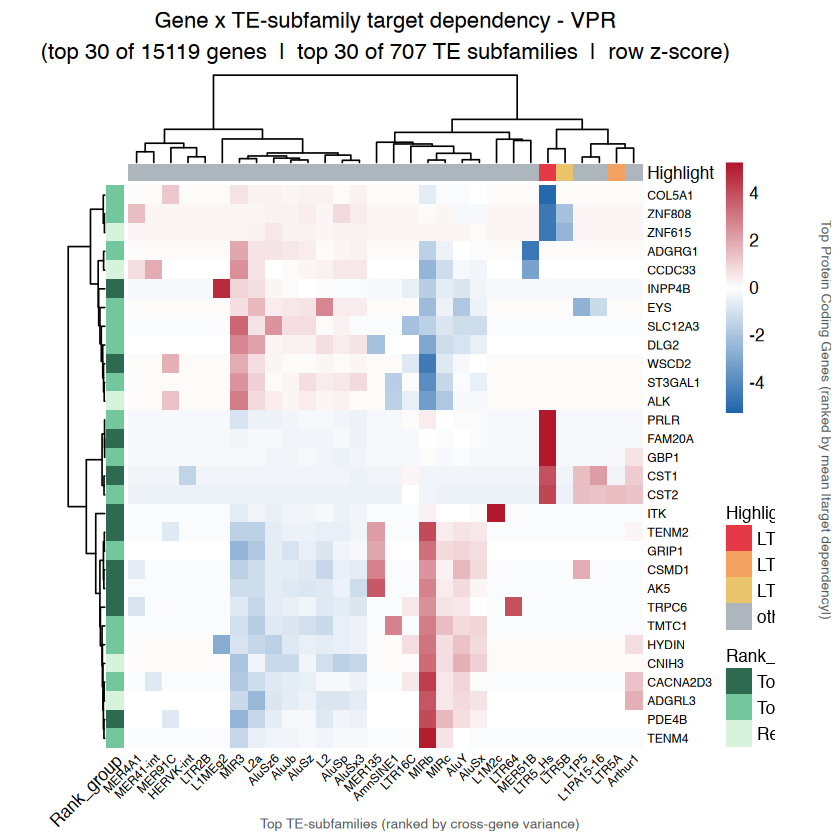

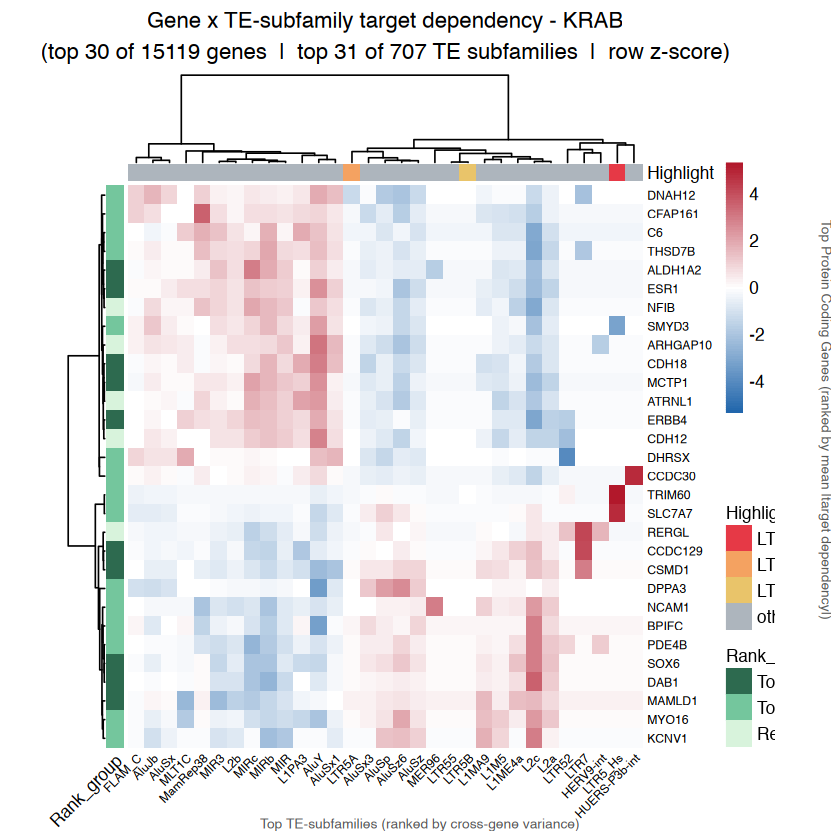

In [243]:
# ── Comparable target contribution heatmaps ────────────
plot_target_matrix_full(
  target_mat_raw   = target_genes_VPR,
  ensembl_to_symbol = ensembl_to_symbol,
  condition_label  = "VPR",
  top_n_genes      = 30,
  top_n_TE         = 30,
  highlight_TEs    = c("LTR5_Hs", "LTR5A", "LTR5B"),
  out_dir          = figures_dir,
  show = TRUE
)

plot_target_matrix_full(
  target_mat_raw   = target_genes_KRAB,
  ensembl_to_symbol = ensembl_to_symbol,
  condition_label  = "KRAB",
  top_n_genes      = 30,
  top_n_TE         = 30,
  highlight_TEs    = c("LTR5_Hs", "LTR5A", "LTR5B"),
  out_dir          = figures_dir,
  show = TRUE
)

In [244]:
# ── Export activity results ─────────────────────────────
saved_activity_results <- save_crates_activity_results(
  input_dir = results_dir,
  act = act,
  A = A,
  sample_conditions = sample_conditions,
  fit_tables = activity_fit_tables,
  target_gene_matrices = list(
    VPR = target_genes_VPR,
    KRAB = target_genes_KRAB
  ),
  extra = list(
    target_summary = target_summary
  ),
  write_tsv = TRUE,
  write_rds = FALSE,
  overwrite = TRUE
)

saved_activity_results


name,format,path
<chr>,<chr>,<chr>
activity_scores,tsv,/Users/vinzent/craTEs/results/results_E_VPR-KRAB_CraTEs_N_c_100_Hg19_craTEs/activity_scores.tsv
sample_activity_diagnostics,tsv,/Users/vinzent/craTEs/results/results_E_VPR-KRAB_CraTEs_N_c_100_Hg19_craTEs/sample_activity_diagnostics.tsv
activity_fit_summary,tsv,/Users/vinzent/craTEs/results/results_E_VPR-KRAB_CraTEs_N_c_100_Hg19_craTEs/activity_fit_summary.tsv
activity_lambda_diagnostics,tsv,/Users/vinzent/craTEs/results/results_E_VPR-KRAB_CraTEs_N_c_100_Hg19_craTEs/activity_lambda_diagnostics.tsv
target_gene_matrix_VPR,tsv,/Users/vinzent/craTEs/results/results_E_VPR-KRAB_CraTEs_N_c_100_Hg19_craTEs/target_gene_matrix_VPR.tsv
target_gene_matrix_KRAB,tsv,/Users/vinzent/craTEs/results/results_E_VPR-KRAB_CraTEs_N_c_100_Hg19_craTEs/target_gene_matrix_KRAB.tsv
target_summary,tsv,/Users/vinzent/craTEs/results/results_E_VPR-KRAB_CraTEs_N_c_100_Hg19_craTEs/target_summary.tsv


## Final summary